In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Familiarization

We start off this assignment by plotting the LIT101 and FIT201 signals from the training and test sets and then reasoning about them.

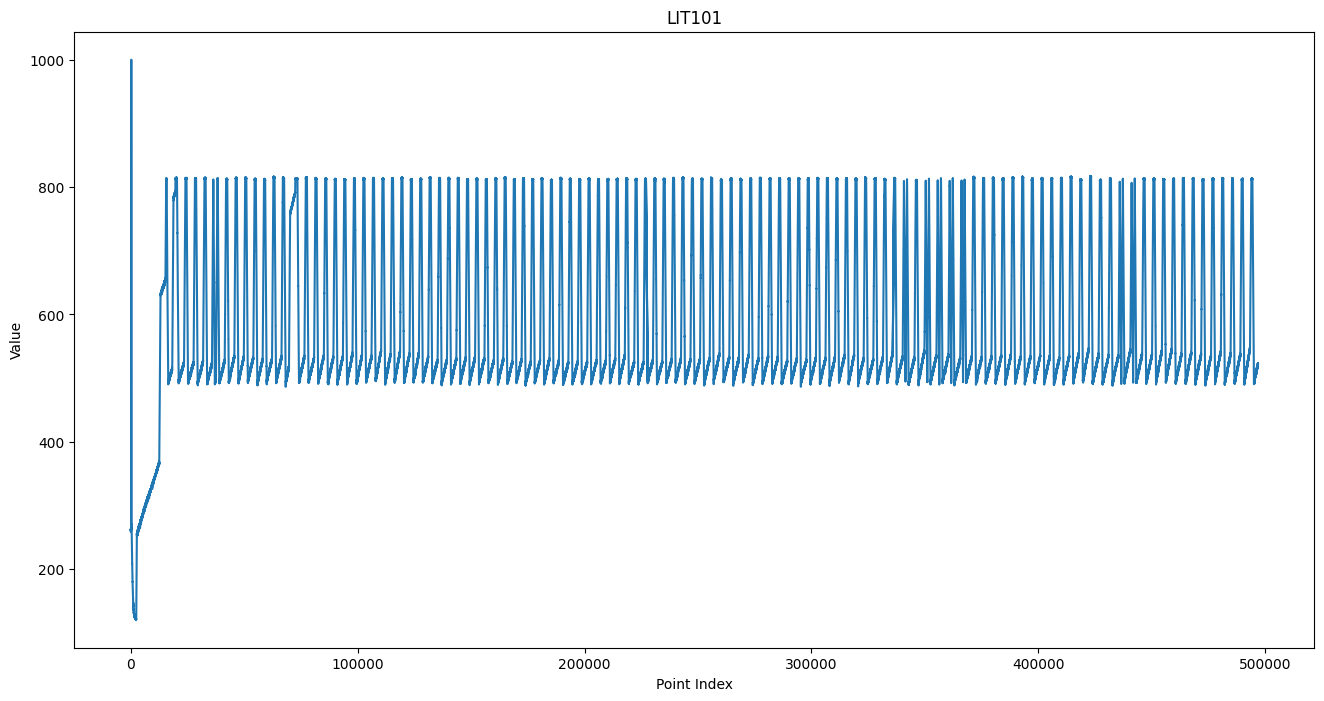

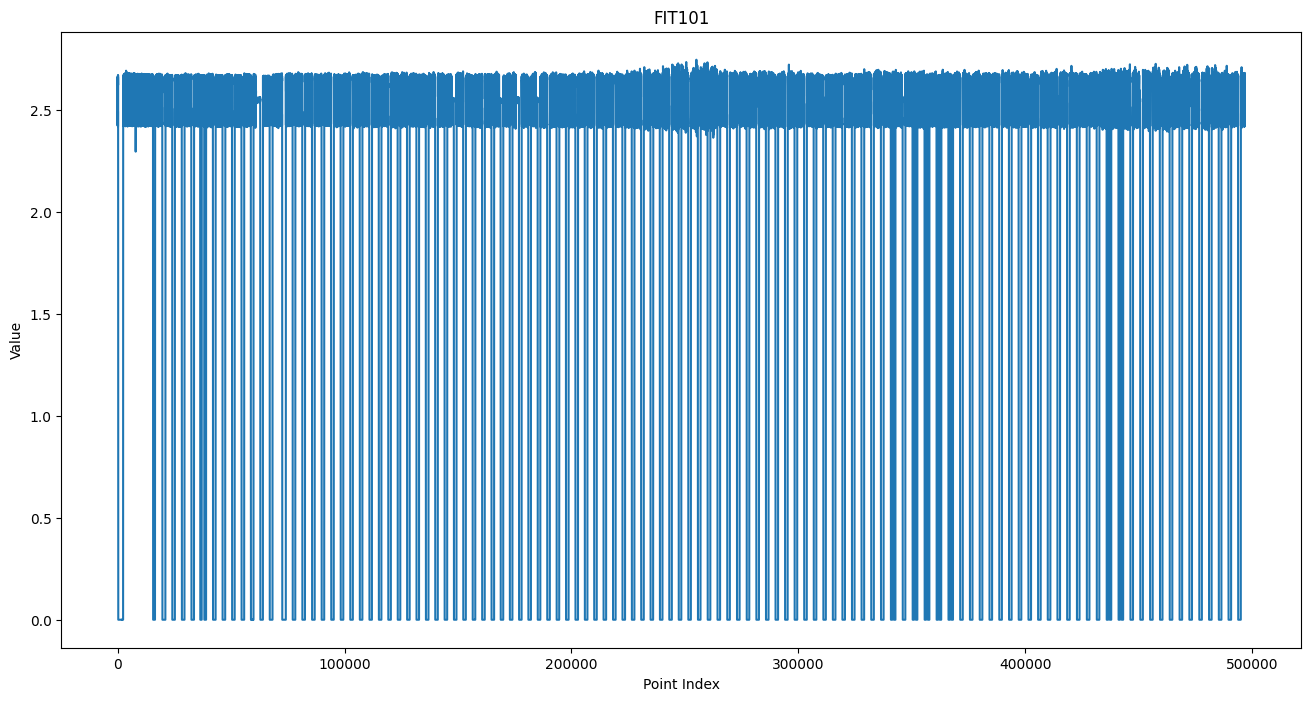

In [18]:
train_data = pd.read_csv("lab1_train.csv")
signalLit = np.array(train_data["LIT101"])
signalFit = np.array(train_data["FIT101"])
plt.figure(figsize=(16, 8))
plt.plot(signalLit)
plt.title("LIT101")
plt.ylabel("Value")
plt.xlabel("Point Index")
plt.figure(figsize=(16, 8))
plt.title("FIT101")
plt.ylabel("Value")
plt.xlabel("Point Index")
plt.plot(signalFit)

From the visualizations above we can see that both the LIT101 and the FIT101 signals display cyclic behavior. We can find out if they are correlated by calculating the correlation matrix.

In [19]:
cor_check = train_data[["LIT101", "FIT101"]].corr()
print(cor_check)

          LIT101    FIT101
LIT101  1.000000 -0.615091
FIT101 -0.615091  1.000000


We see that the two signals have a correlation value of -0.615091 which means that they are negatively correlated, so if one increases the other decreases.

# DTW

We begin by importing our training and testing data. We chose to use the "LIT1010" signal as it shows interesting cyclic behavior. We choose to drop the first 15000 points of the train data as it is unrepresentative when compared to the rest of the signal.

We plot these signals for the train and the test data as well.

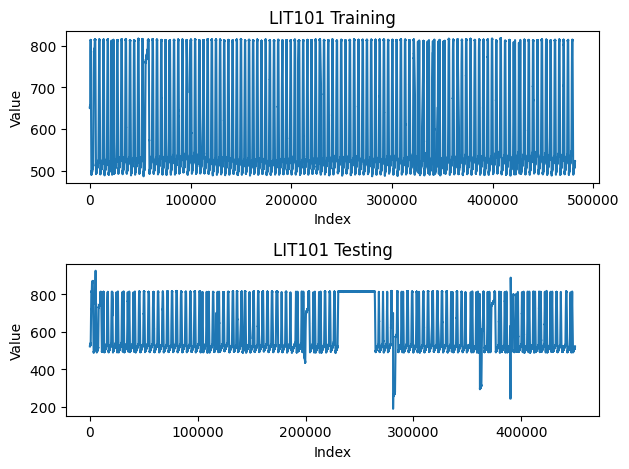

In [20]:
train_data = pd.read_csv("lab1_train.csv")
train_data = train_data.drop(columns=["Timestamp", "Normal/Attack"])

test_data = pd.read_csv("lab1_test.csv")
test_data = test_data.drop(columns=["Timestamp", "Normal/Attack"])

signal = np.array(train_data["LIT101"][15000:])
signal_test = np.array(test_data["LIT101"])

figure, axis = plt.subplots(2, 1)
axis[0].plot(signal)
axis[0].set_title("LIT101 Training")
axis[0].set_xlabel("Index")
axis[0].set_ylabel("Value")
axis[1].plot(signal_test)
axis[1].set_title("LIT101 Testing")
axis[1].set_xlabel("Index")
axis[1].set_ylabel("Value")
figure.tight_layout()
plt.show()

From our training set we pick out three representative windows ranging from 17000:37000, 150000:170000 and 320000:340000. We also visualize them below.

Text(0.5, 0, 'Point')

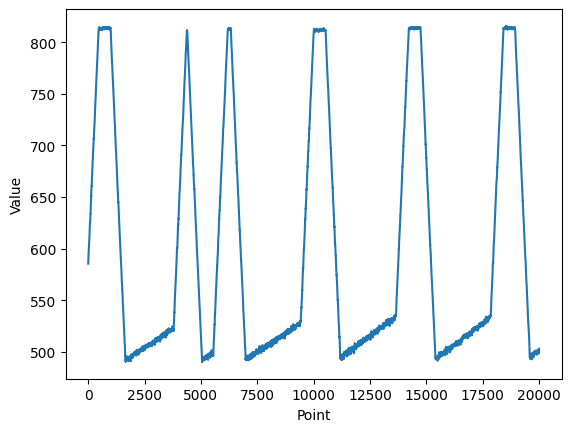

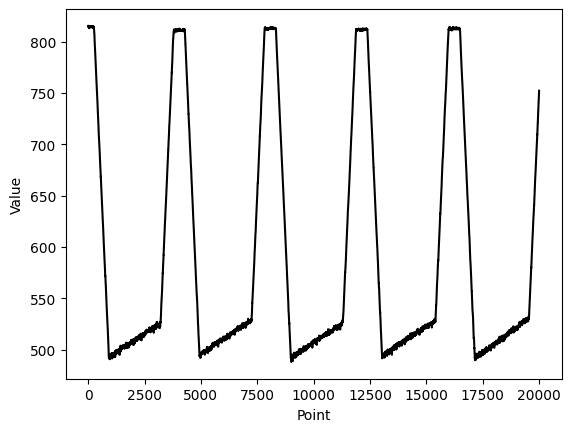

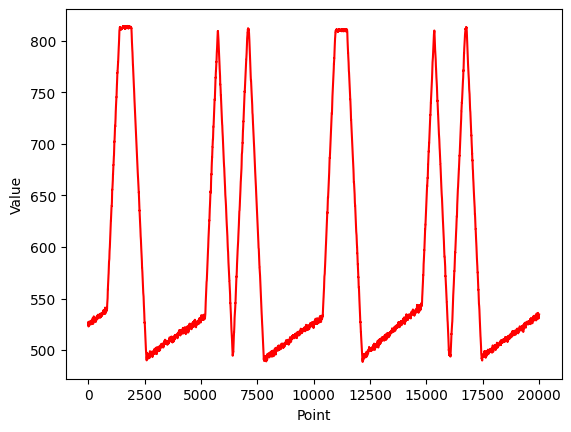

In [21]:
rep_window_1 = signal[17000:37000]
rep_window_2 = signal[150000:170000]
rep_window_3 = signal[320000:340000]

plt.figure()
plt.plot(rep_window_1, label = "Window 1")
plt.ylabel("Value")
plt.xlabel("Point")

plt.figure()
plt.plot(rep_window_2, label = "Window 2", color = "black")
plt.ylabel("Value")
plt.xlabel("Point")

plt.figure()
plt.plot(rep_window_3, label = "Window 3", color = "r")
plt.ylabel("Value")
plt.xlabel("Point")

With these representative training windows, we now construct them into sliding windows.

We pick the size as 10000 because it provides a good balance between the noise in the data and the resolution. We pick the stride to be 30% of the window size as it provides a good trade off between accuracy and performance.

We use the same thought process to pick the size and stride for the testing data sliding windows, but we use 20% of the size as the stride.

In [22]:
size_train = 10000
stride_train = 3000

rep_window_1_sliding = np.lib.stride_tricks.sliding_window_view(rep_window_1, size_train)[::stride_train]
rep_window_2_sliding = np.lib.stride_tricks.sliding_window_view(rep_window_2, size_train)[::stride_train]
rep_window_3_sliding = np.lib.stride_tricks.sliding_window_view(rep_window_3, size_train)[::stride_train]
rep_windows = [rep_window_1_sliding, rep_window_2_sliding, rep_window_3_sliding]

size_test = 10000
stride_test = 2000
sliding_test_windows = np.lib.stride_tricks.sliding_window_view(signal_test, size_test)[::stride_test]

With this, we can now proceed with the dynamic time warping distance calculation between the 2 sets.

As the number of points in each window is still quite large, we randomly sample 3500 out of the 10000 points from each window and then calculate the DTW distance with these points. We append to the "dtw_distances" array the distance of the test points to their closest representative window. 

We also make use of fast DTW with k = 5 to speed up the process at the cost of slightly reduced accuracy. (This takes approximately 3 minutes to run on our machines)

In [23]:
def fast_dynamic_time_warping(a, b):
    n = a.size
    m = b.size
    dp = np.full((n + 1, m + 1), np.inf)
    dp[0, 0] = 0
    k = 5
    for i in range(1, n + 1):
        for j in range(max(1, i - k), min(m + 1, i + k + 1)):
            dp[i, j] = (a[i - 1] - b[j - 1]) ** 2 + min(dp[i - 1, j], dp[i, j - 1], dp[i - 1, j - 1])

    dtw_distance = np.sqrt(dp[n, m])
    return dtw_distance

indices = np.arange(0, 9999)
sample1 = np.random.choice(indices, size = 3500)
np.sort(sample1)
sample2 = np.random.choice(indices, size = 3500)
np.sort(sample2)
sample3 = np.random.choice(indices, size = 3500)
np.sort(sample3)
samples = [sample1, sample2, sample3]

dtw_distances = []
windows_with_distances = []
for window in sliding_test_windows:
    distance = np.inf
    for i in range(3):
        for r_window in rep_windows[i]:
            distance = min(distance, fast_dynamic_time_warping(window[samples[i]], r_window[samples[i]]))
    dtw_distances.append(distance)
    windows_with_distances.append((window, distance))

Finally, we plot these DTW distances onto a graph and set an estimated threshold value by observing the plot.

With DTW, we expect to detect contextual anomalies so sequences in the test data that are "misaligned" or have unexpected shifts when compared to reference sequences.

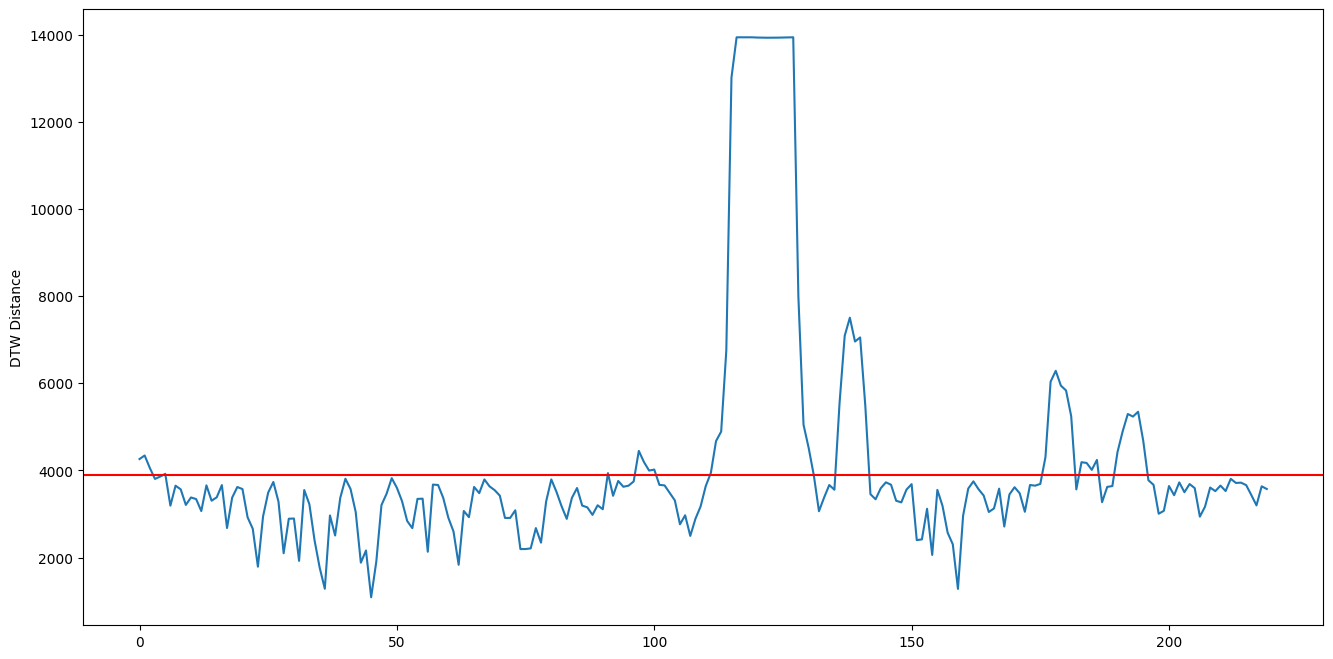

In [24]:
t = 3900.0
plt.figure(figsize=(16, 8))
plt.plot(dtw_distances, label="DTW Distances")
plt.axhline(y = t, color='r')
plt.ylabel("DTW Distance")
plt.show()

If the distance is above the threshold value, we classify all the points in that test data window as anomalous.

In [25]:
dtw_anomalies = []
for i in windows_with_distances:
    if(i[1] > t):
        dtw_anomalies.append(i[0])

dtw_anomalies = np.array(dtw_anomalies) # Array containing all the anomalous windows     

# PCA

For the first step in the PCA process, we import our training data and normalize it using the mean shifting method.

In [26]:
train_data = pd.read_csv("lab1_train.csv")
train_data = train_data.drop(columns=["Timestamp", "Normal/Attack"])

np_data = train_data.to_numpy()
normal_data = np_data - np.mean(np_data, axis = 0)

Then, for the normalized data we calculate the eigenvalues and the corresponding eigenvectors. We sort this descendingly based on the value of the eigenvalues, i.e. in terms of the greatest variance.

In [27]:
def principal_component_analysis(df, k):
    eigenvectors = np.zeros(shape=(df.shape[1], k))
    cov_matrix = np.cov(df, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
    sorted_indices = np.argsort(eigenvalues)[::-1]
    sorted_eigenvectors = eigenvectors[:, sorted_indices]
    eigenvectors = sorted_eigenvectors[:, :k]
    return eigenvalues[sorted_indices], eigenvectors

eigenvalues, eigenvectors = principal_component_analysis(normal_data, len(normal_data[0]))

We then plot the explained variance graph and then apply the elbow method to find a suitable value for the number of eigenvectors to use for the projection.

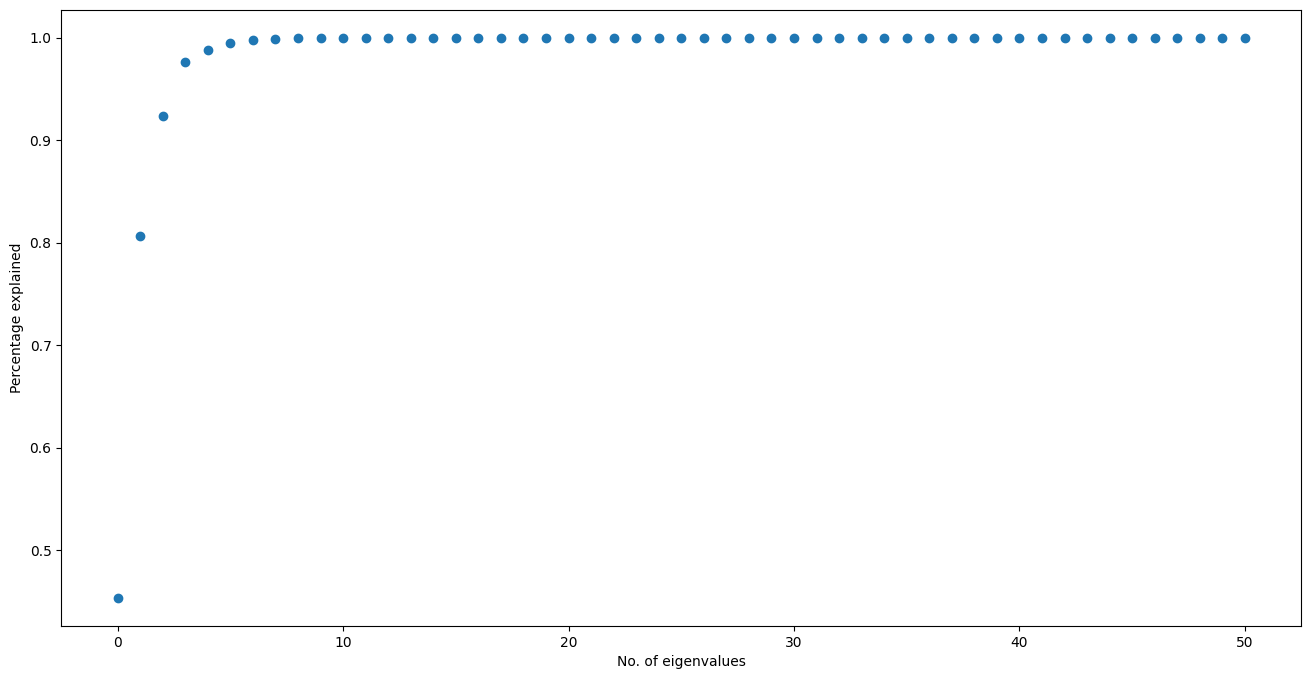

In [28]:
eigen_sum = np.sum(eigenvalues)
eigen_matrix = []
sum = 0
for i in range(len(normal_data[0])):
    sum += eigenvalues[i] / eigen_sum
    eigen_matrix.append(sum)

plt.figure(figsize=(16,8))
plt.scatter(x = np.array([i for i in range(len(normal_data[0]))]), y = eigen_matrix)
plt.ylabel("Percentage explained")
plt.xlabel("No. of eigenvalues")
plt.show()

Based on what we see above, we can conclude that k = 5 is a suitable value for the number of eigenvectors as it is the "elbow" of the graph. We then project our normalized data to the component space by taking its dot product with the first 5 eigenvectors.

In [29]:
def apply_principal_component_analysis(df, eigenvectors):
    # We don't normalize df in the method, as we always provide a normalized df to it
    projected_data = np.dot(df, eigenvectors)
    return pd.DataFrame(projected_data)

k = 5
projected_data = apply_principal_component_analysis(normal_data, eigenvectors[:, :k])

We then reproject the data back to the raw data space by taking the dot product with the transpose of the first 5 eigenvectors, as the inverse of an orthogonal matrix is its transpose. Then, we calculate the residuals, i.e. the differences between the original normalized data points and the reprojected data points and plot this. We use the Euclidean distance for this.

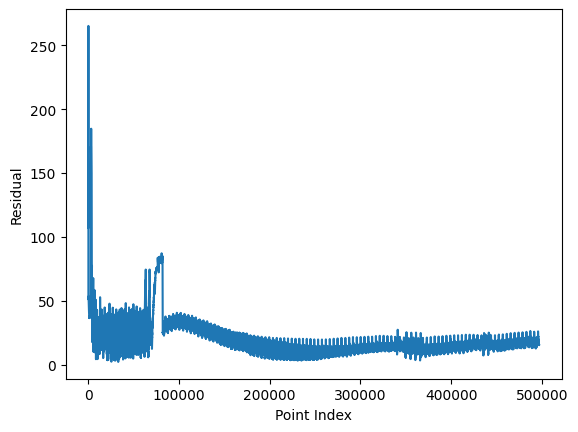

In [30]:
reprojected_data = apply_principal_component_analysis(projected_data, eigenvectors[:, :k].T)
residuals = np.sqrt(np.sum((normal_data - reprojected_data) ** 2, axis = 1))

plt.ylabel("Residual")
plt.xlabel("Point Index")
plt.plot(residuals)

From the residuals graph above we can that there seems to be some noise in the training set indicated by the relatively large residuals. We clean up our training set by only considering points from it that have a residual below a certain threshold, we chose this threshold to be 25 after some trial and error.

With this cleaned data set, we again calculate the eigenvalues and eigenvectors, sorted them as before. We then again use the elbow method to choose our value for k. This time we take k = 4.

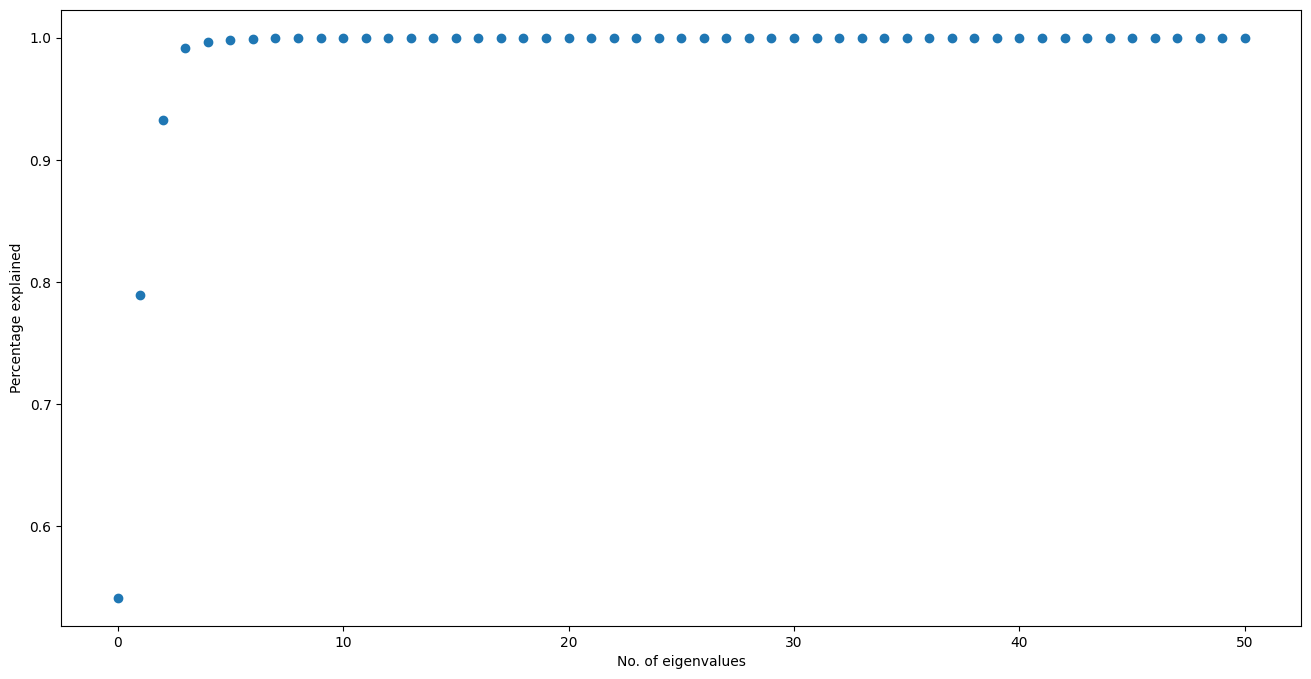

In [31]:
cleaned_data = normal_data[np.where(residuals < 25)]

eigenvalues, eigenvectors = principal_component_analysis(cleaned_data, len(cleaned_data[0]))
eigen_sum = np.sum(eigenvalues)
eigen_matrix = []
sum = 0
for i in range(len(cleaned_data[0])):
    sum += eigenvalues[i] / eigen_sum
    eigen_matrix.append(sum)

plt.figure(figsize=(16,8))
plt.ylabel("Percentage explained")
plt.xlabel("No. of eigenvalues")
plt.scatter(x = np.array([i for i in range(len(cleaned_data[0]))]), y = eigen_matrix)
plt.show()

We then project our cleaned data and the test data into the component space by taking the dot product with first 4 eigenvectors of the cleaned data.

Following this, we calculate the residuals, using Euclidean distance, between the projected test data and the projected cleaned data. Finally, we plot this and by observing the plot we pick a threshold value. If a point has a residual above this threshold we classify it as anomalous.

With PCA we expect to detect point anomalies in our test set i.e. the data points that deviate significantly from the overall distribution of the features in the dataset.

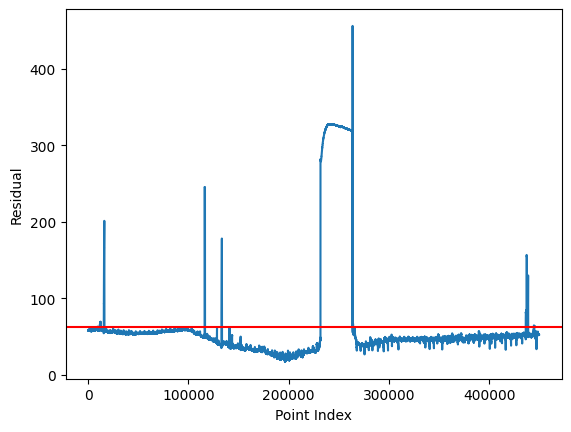

In [32]:
k = 4
projected_data = apply_principal_component_analysis(cleaned_data, eigenvectors[:, :k])

test_data = pd.read_csv("lab1_test.csv")
test_data = test_data.drop(columns=["Timestamp", "Normal/Attack"])

np_test_data = test_data.to_numpy()
normal_test_data = np_test_data - np.mean(np_test_data, axis = 0)
projected_test_data = apply_principal_component_analysis(normal_test_data, eigenvectors[:, :k])
reprojected_test_data = apply_principal_component_analysis(projected_test_data, eigenvectors[:, :k].T)
test_residuals = np.sqrt(np.sum((normal_test_data - reprojected_test_data) ** 2, axis = 1))
plt.ylabel("Residual")
plt.xlabel("Point Index")
plt.plot(test_residuals)
t = 62.5
plt.axhline(y = t, color = 'r')

For every point index we check the test_residuals array to see if that residual is above the threshold, if it is we classify the value corresponding to that index in the test set as anomalous.

In [33]:
indices = []
index = 0
for i in test_residuals:
    if(i > t):
        indices.append(index)
    index += 1

pca_anomalies = np_test_data[np.array(indices)] # Array containing all the anomalous values